# Math and diagrams

LaTeX formulas and a Mermaid flowchart, both drawn without any tool beyond Python.

Run it as ``python 08_math_and_diagrams.py`` or open ``08_math_and_diagrams.ipynb`` to see each step.

In [1]:
import os
import tempfile
from pathlib import Path

import svgwriter as svg

`svg.latex` typesets a formula as vector outlines (a group of paths). It uses TeX when `latex` and
`dvisvgm` are installed, otherwise Ziamath (`pip install "pysvgwriter[math]"`) and then matplotlib's mathtext.
The result is an ordinary element: scale, colour, place and export it like any other.

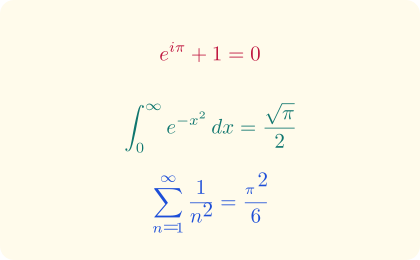

In [2]:
WIDTH, HEIGHT = 420, 260
FORMULAS = (
    (r"e^{i\pi} + 1 = 0", "#be123c"),
    (r"\int_0^\infty e^{-x^2}\,dx = \frac{\sqrt{\pi}}{2}", "#0f766e"),
    (r"\sum_{n=1}^{\infty} \frac{1}{n^2} = \frac{\pi^2}{6}", "#1d4ed8"),
)

formulas = svg.Document(WIDTH, HEIGHT)
formulas.rect(0, 0, WIDTH, HEIGHT, rx=14, fill="#fffbeb")
for index, (source, color) in enumerate(FORMULAS):
    formula = svg.latex(source, display=True).update(fill=color)
    formulas.add(formula.scale(2.1).place(WIDTH / 2, 52 + index * 76))
formulas

`Document.open` reads Mermaid files. Flowcharts (`graph` / `flowchart`) are parsed and laid out by
svgwriter itself when the Mermaid CLI is missing, so this needs no external tool.

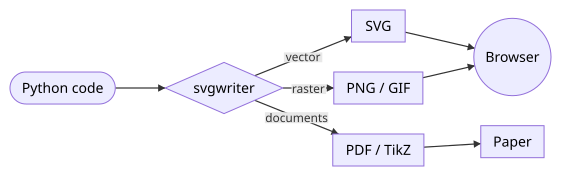

In [3]:
FLOWCHART = """flowchart LR
    A([Python code]) --> B{svgwriter}
    B -->|vector| C[SVG]
    B -->|raster| D[PNG / GIF]
    B -->|documents| E[PDF / TikZ]
    C --> F((Browser))
    D --> F
    E --> G[[Paper]]
"""

source = Path(tempfile.mkdtemp(prefix="svgwriter-")) / "flow.mmd"
source.write_text(FLOWCHART, encoding="utf-8")
flow = svg.Document.open(source)
flow

The imported diagram is made of native elements, so it can be edited or exported to any format.
Set `SVGWRITER_EXAMPLES_OUT` to choose the folder for the saved pictures.

In [4]:
out = Path(os.environ.get("SVGWRITER_EXAMPLES_OUT") or tempfile.mkdtemp(prefix="svgwriter-"))
out.mkdir(parents=True, exist_ok=True)
formulas.save(out / "08_math.svg")
flow.save(out / "08_flowchart.svg")
print("saved 08_math.svg and 08_flowchart.svg")

saved 08_math.svg and 08_flowchart.svg
